# Customer Churn Analysis — Telco
### Why are customers leaving, and which customers are most likely to churn?

**Provenance first.** This notebook runs on the public **IBM Telco Customer Churn** sample
(7,043 rows, one row per customer, no time dimension). It is a widely used reference dataset, not a
live Telco extract. Consequences you should carry into every number below: there is **one snapshot and
no month dimension**, so nothing here can be called a trend, and "revenue at risk" is a run-rate
exposure, not a realised loss.

**Definitions used** (identical to `sql/01_data_exploration.sql`, enforced by an integrity gate):

| Term | Definition |
|---|---|
| Churn rate | `COUNT(churned) / COUNT(customers)`, one row per customer |
| Churned | `Churn == 'Yes'` |
| New customer | `tenure <= 12` months |
| Revenue at risk | `SUM(MonthlyCharges)` over churned customers, annualised x12 |
| Prime risk | Month-to-month **and** tenure <= 12 **and** Fiber optic **and** no tech support |

Expected outputs are asserted at the end of the notebook against the SQL views — if pandas and SQL
disagree, the notebook fails.


In [1]:
import pandas as pd, numpy as np, sqlite3, warnings
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import math, os
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda v: f"{v:,.2f}")
sns.set_theme(style='whitegrid')
PAL = ['#2E86AB', '#E4572E', '#F4A259', '#0B6E4F', '#6B4E71']
ACCENT, MUTED = '#E4572E', '#2E86AB'
FIG = 'reports/figures' if os.path.exists('reports') else '../reports/figures'
os.makedirs(FIG, exist_ok=True)
from IPython.display import Image, display
def save_and_show(fig, name):
    # save to reports/figures and embed, so the notebook reads standalone
    p = f'{FIG}/{name}.png'
    fig.savefig(p, dpi=150, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=p))
print('pandas', pd.__version__, '| seaborn', sns.__version__)

pandas 2.3.3 | seaborn 0.13.2


## 1. Load and clean

`TotalCharges` arrives as text with 11 blank strings. All 11 belong to customers with `tenure = 0`,
i.e. never billed. Filling `0.0` is the only reading consistent with that; dropping the rows would
delete the highest-risk cohort in the file.

In [2]:
ROOT = '..' if os.path.exists('../data') else '.'
df = pd.read_csv(f'{ROOT}/data/raw/customer_churn.csv')
print('raw shape:', df.shape)

blank = df['TotalCharges'].astype(str).str.strip() == ''
print('blank TotalCharges :', int(blank.sum()))
print('their tenure values:', sorted(df.loc[blank, 'tenure'].unique().tolist()))
print('their churn labels :', df.loc[blank, 'Churn'].value_counts().to_dict())

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0.0)
df['churn_flag'] = df.Churn.eq('Yes').astype(int)
df['tenure'] = df.tenure.astype(int)
print('\nnulls after cleaning:', int(df.isna().sum().sum()))
print('churned             :', int(df.churn_flag.sum()))

raw shape: (7043, 21)
blank TotalCharges : 11
their tenure values: [0]
their churn labels : {'No': 11}

nulls after cleaning: 0
churned             : 1869


## 2. Data quality

Structural checks only — the substantive issue with this dataset is definitional, not structural.

In [3]:
checks = {
    'rows': len(df),
    'columns': df.shape[1],
    'total nulls': int(df.isna().sum().sum()),
    'duplicate customerID': int(df.customerID.duplicated().sum()),
    'duplicate full rows': int(df.duplicated().sum()),
    'negative MonthlyCharges': int((df.MonthlyCharges < 0).sum()),
    'tenure out of 0-72': int(((df.tenure < 0) | (df.tenure > 72)).sum()),
    'Churn values': df.Churn.nunique(),
    'date columns': 0,
}
pd.DataFrame(checks.items(), columns=['check', 'value']).to_markdown(index=False)

'| check                   |   value |\n|:------------------------|--------:|\n| rows                    |    7043 |\n| columns                 |      22 |\n| total nulls             |       0 |\n| duplicate customerID    |       0 |\n| duplicate full rows     |       0 |\n| negative MonthlyCharges |       0 |\n| tenure out of 0-72      |       0 |\n| Churn values            |       2 |\n| date columns            |       0 |'

## 3. Headline KPIs

The churn rate is **26.54%** of 7,043 customers. The 95% Wilson interval is **[25.52%, 27.58%]** —
any segment claim must clear that band to be interesting.

In [4]:
n, k = len(df), int(df.churn_flag.sum())
base = k / n
z = 1.96
den = 1 + z*z/n
centre = (base + z*z/(2*n)) / den
half = z*math.sqrt(base*(1-base)/n + z*z/(4*n*n)) / den
ci = ((centre-half)*100, (centre+half)*100)

mrr = df.MonthlyCharges.sum()
mrr_churned = df.loc[df.churn_flag==1, 'MonthlyCharges'].sum()

kpi = pd.DataFrame([
    ('Customers', f'{n:,}', ''),
    ('Churned', f'{k:,}', ''),
    ('Churn rate', f'{base*100:.2f}%', f'95% CI [{ci[0]:.2f}%, {ci[1]:.2f}%]'),
    ('Retention rate', f'{(1-base)*100:.2f}%', ''),
    ('Avg tenure — churned', f"{df.loc[df.churn_flag==1,'tenure'].mean():.1f} mo", ''),
    ('Avg tenure — retained', f"{df.loc[df.churn_flag==0,'tenure'].mean():.1f} mo", ''),
    ('Avg monthly charge — churned', f"${df.loc[df.churn_flag==1,'MonthlyCharges'].mean():.2f}", ''),
    ('Avg monthly charge — retained', f"${df.loc[df.churn_flag==0,'MonthlyCharges'].mean():.2f}", ''),
    ('MRR total', f'${mrr:,.2f}', ''),
    ('MRR attached to churners', f'${mrr_churned:,.2f}', f'{mrr_churned/mrr*100:.2f}% of MRR'),
    ('Annualised revenue at risk', f'${mrr_churned*12:,.2f}', 'run-rate, not realised loss'),
], columns=['KPI', 'Value', 'Note'])
kpi.to_markdown(index=False)

'| KPI                           | Value         | Note                        |\n|:------------------------------|:--------------|:----------------------------|\n| Customers                     | 7,043         |                             |\n| Churned                       | 1,869         |                             |\n| Churn rate                    | 26.54%        | 95% CI [25.52%, 27.58%]     |\n| Retention rate                | 73.46%        |                             |\n| Avg tenure — churned          | 18.0 mo       |                             |\n| Avg tenure — retained         | 37.6 mo       |                             |\n| Avg monthly charge — churned  | $74.44        |                             |\n| Avg monthly charge — retained | $61.27        |                             |\n| MRR total                     | $456,116.60   |                             |\n| MRR attached to churners      | $139,130.85   | 30.50% of MRR               |\n| Annualised revenue at ris

## 4. Contract type is the strongest single driver

Month-to-month customers churn at **42.71%** against **2.83%** on two-year contracts — a 15x spread,
chi-square p ≈ 5.9e-258, Cramér's V 0.410 (the strongest association in the dataset).
The segment matters more than its size: month-to-month is **55.02%** of the base but **88.55%** of all
churners.

chi2=1184.6  p=5.86e-258  CramersV=0.410


churn_flag      customers  churners  churn_rate_%  share_of_base_%  share_of_churners_%
Contract                                                                               
Month-to-month       3875      1655         42.71            55.02                88.55
One year             1473       166         11.27            20.91                 8.88
Two year             1695        48          2.83            24.07                 2.57


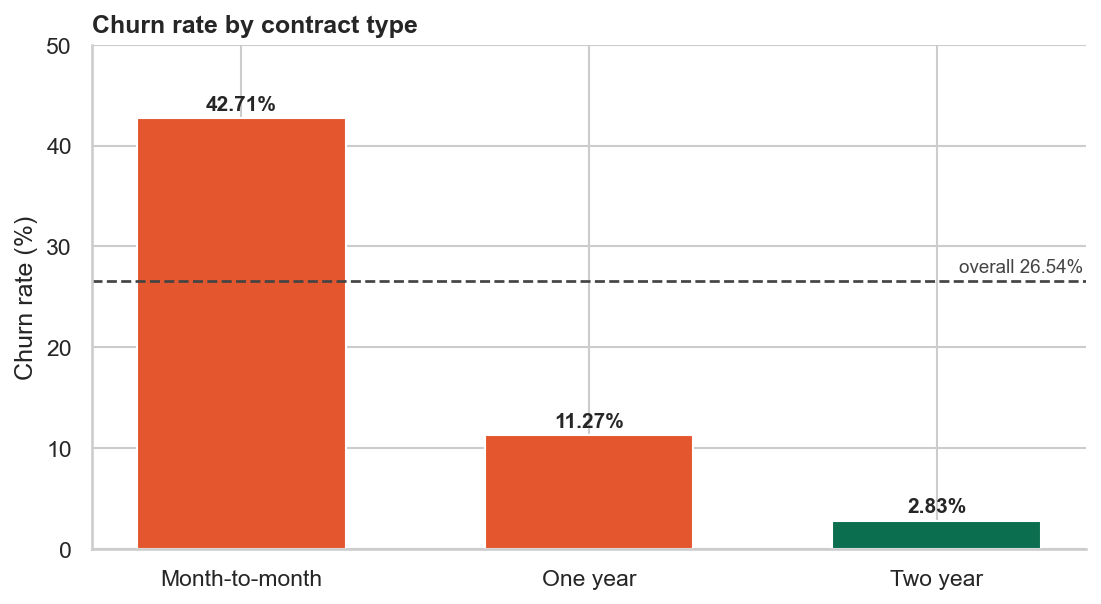

In [5]:
ct = pd.crosstab(df.Contract, df.churn_flag)
ct['customers'] = ct.sum(axis=1); ct['churners'] = ct[1]
ct['churn_rate_%'] = ct['churners']/ct['customers']*100
ct['share_of_base_%'] = ct['customers']/n*100
ct['share_of_churners_%'] = ct['churners']/k*100
chi2, p, dof, exp = stats.chi2_contingency(ct[[0,1]].values)
V = math.sqrt(chi2/(n*(min(ct.shape[0]-1,1))))
ct_order = ct.reindex(['Month-to-month','One year','Two year'])
print(f'chi2={chi2:.1f}  p={p:.3g}  CramersV={V:.3f}')
print(ct_order[['customers','churners','churn_rate_%','share_of_base_%','share_of_churners_%']].round(2).to_string())

fig, ax = plt.subplots(figsize=(7.5,4.2))
d = ct_order['churn_rate_%']
bars = ax.bar(d.index, d.values, color=[ACCENT, PAL[1], PAL[3]], width=.6)
ax.axhline(base*100, ls='--', lw=1.3, color='#444')
ax.text(2.42, base*100+0.9, f'overall {base*100:.2f}%', fontsize=9, color='#444', ha='right')
for b, v in zip(bars, d.values):
    ax.text(b.get_x()+b.get_width()/2, v+.8, f'{v:.2f}%', ha='center', fontweight='bold', fontsize=10)
ax.set_ylabel('Churn rate (%)'); ax.set_ylim(0, 50)
ax.set_title('Churn rate by contract type', fontsize=12, fontweight='bold', loc='left')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); save_and_show(fig, '01_churn_by_contract')

## 5. Churn is an early-life problem

Churn falls monotonically with tenure: **52.94%** in months 0-6 down to **6.61%** in months 61-72.
**55.48%** of all churners leave within their first 12 months, while new customers are only **31.04%**
of the base. First-year retention is therefore the highest-leverage intervention available in this
dataset.

churn_flag  customers  churners  churn_rate_%  cum_%_of_churners
tenure                                                          
0-6              1481       784         52.94              41.95
7-12              705       253         35.89              55.48
13-24            1024       294         28.71              71.21
25-36             832       180         21.63              80.85
37-48             762       145         19.03              88.60
49-60             832       120         14.42              95.02
61-72            1407        93          6.61             100.00

churners within 12 months : 1037 (55.48% of all churners)
new customers in base     : 2186 (31.04% of base)


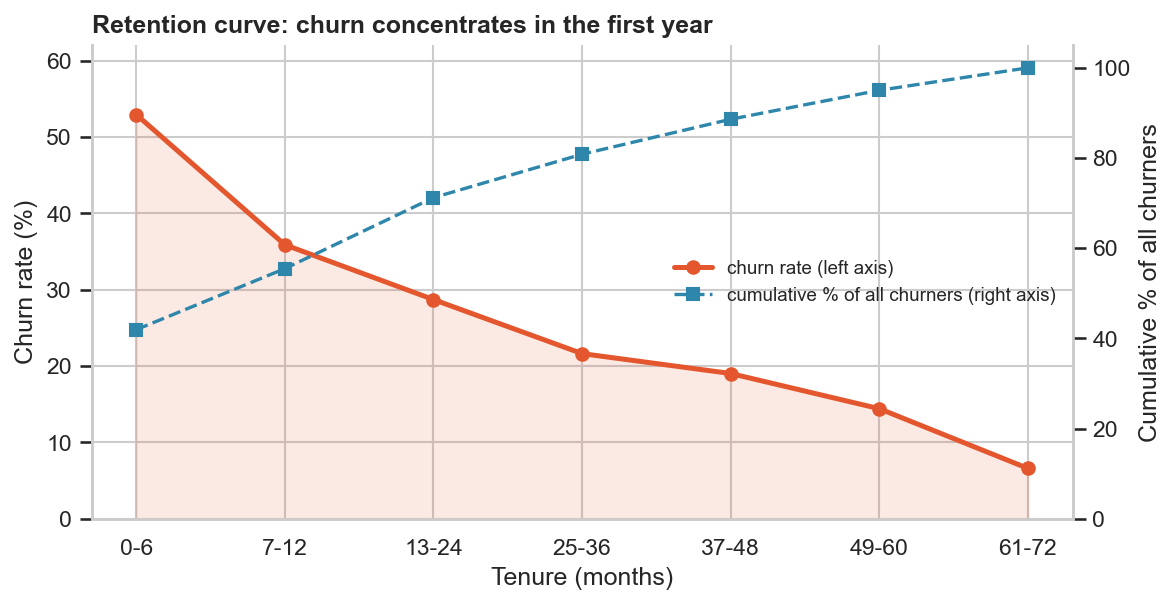

In [6]:
bands = pd.cut(df.tenure, [-1,6,12,24,36,48,60,72],
                labels=['0-6','7-12','13-24','25-36','37-48','49-60','61-72'])
tb = pd.crosstab(bands, df.churn_flag)
tb['customers'] = tb.sum(axis=1); tb['churners'] = tb[1]
tb['churn_rate_%'] = tb['churners']/tb['customers']*100
tb['cum_%_of_churners'] = tb['churners'].cumsum()/k*100
print(tb[['customers','churners','churn_rate_%','cum_%_of_churners']].round(2).to_string())
print()
print(f"churners within 12 months : {int(df[(df.churn_flag==1)&(df.tenure<=12)].shape[0])} "
      f"({df[(df.churn_flag==1)&(df.tenure<=12)].shape[0]/k*100:.2f}% of all churners)")
print(f"new customers in base     : {int((df.tenure<=12).sum())} ({(df.tenure<=12).mean()*100:.2f}% of base)")

fig, ax = plt.subplots(figsize=(8,4.2))
x = np.arange(len(tb))
ax.plot(x, tb['churn_rate_%'], marker='o', lw=2.4, color=ACCENT, label='churn rate (left axis)')
ax.set_ylim(0, 62)
ax.fill_between(x, tb['churn_rate_%'], alpha=.13, color=ACCENT)
ax.set_xticks(x); ax.set_xticklabels(tb.index)
ax.set_xlabel('Tenure (months)'); ax.set_ylabel('Churn rate (%)')
ax2 = ax.twinx()
ax2.plot(x, tb['cum_%_of_churners'], marker='s', ls='--', lw=1.6, color=MUTED, label='cumulative % of all churners (right axis)')
ax2.set_ylabel('Cumulative % of all churners'); ax2.set_ylim(0,105)
ax2.grid(False)
ax.set_title('Retention curve: churn concentrates in the first year', fontsize=12, fontweight='bold', loc='left')
h1,l1 = ax.get_legend_handles_labels(); h2,l2 = ax2.get_legend_handles_labels()
ax.legend(h1+h2, l1+l2, loc='center right', fontsize=9, frameon=False)
ax.spines[['top']].set_visible(False); ax2.spines[['top']].set_visible(False)
fig.tight_layout(); save_and_show(fig, '02_retention_curve')

## 6. Higher bills churn more — but this is confounded

Customers paying $70-89 churn at **37.95%** versus **9.80%** under $30. Before writing "price drives
churn", note *why* that is unsafe: fiber customers pay more **and** churn more, so the charge band is
partly a proxy for product. The multivariate model in §9 confirms the confounding — once tenure and
product mix are controlled, the sign of the charge coefficient reverses. Report the univariate pattern,
do not claim causation from it.

churn_flag      customers  churners  churn_rate_%
MonthlyCharges                                   
<30                  1653       162          9.80
30-49                 641       199         31.05
50-69                1158       234         20.21
70-89                1847       701         37.95
90+                  1744       573         32.86


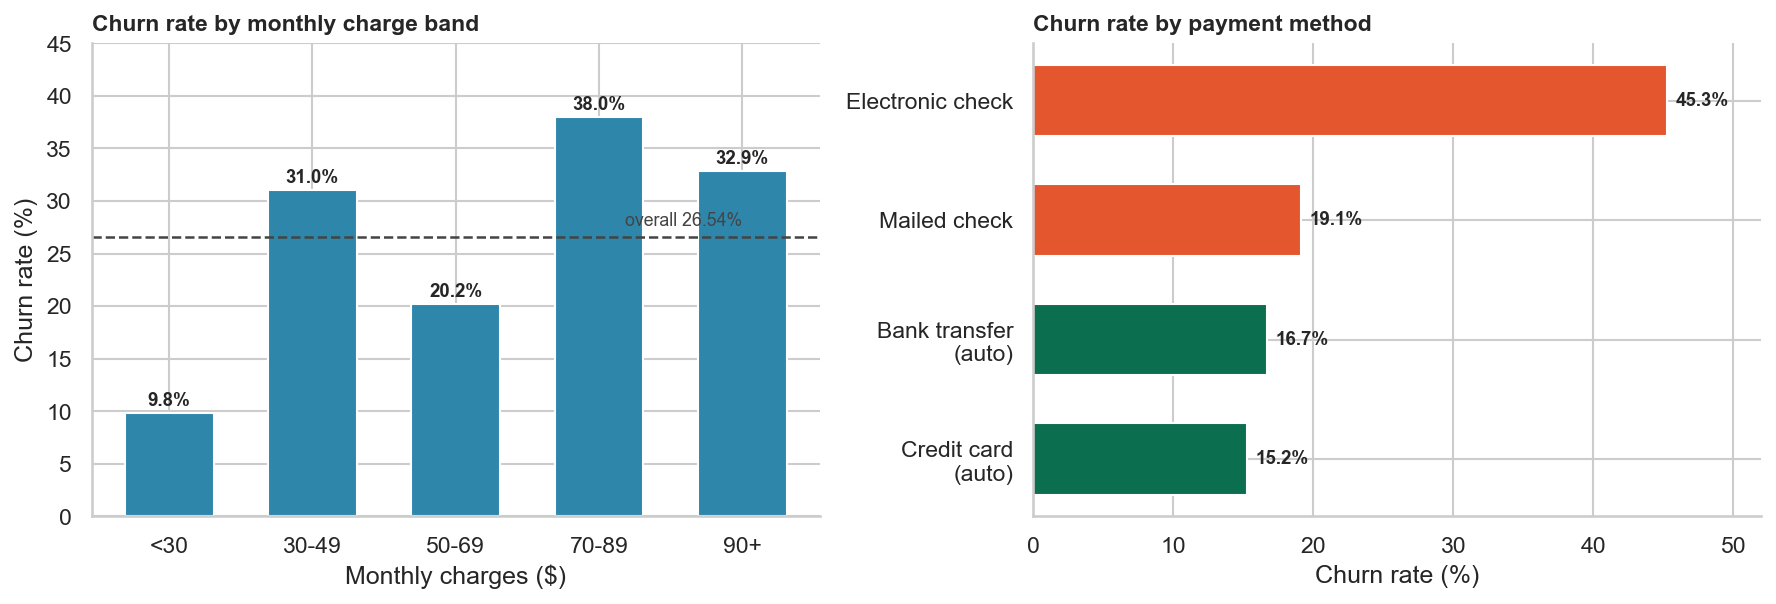

churn_flag                 customers  churners  rate
PaymentMethod                                       
Credit card (automatic)         1522       232 15.24
Bank transfer (automatic)       1544       258 16.71
Mailed check                    1612       308 19.11
Electronic check                2365      1071 45.29


In [7]:
cb = pd.cut(df.MonthlyCharges, [0,30,50,70,90,200], labels=['<30','30-49','50-69','70-89','90+'],
            right=False)   # left-closed, matching the SQL charge_band definition exactly
cbt = pd.crosstab(cb, df.churn_flag)
cbt['customers']=cbt.sum(axis=1); cbt['churners']=cbt[1]; cbt['churn_rate_%']=cbt['churners']/cbt['customers']*100
print(cbt[['customers','churners','churn_rate_%']].round(2).to_string())

fig, axes = plt.subplots(1,2, figsize=(12,4.2))
axes[0].bar(cbt.index.astype(str), cbt['churn_rate_%'], color=PAL[0], width=.62)
axes[0].axhline(base*100, ls='--', lw=1.2, color='#444')
axes[0].text(len(cbt)-1, base*100+1.1, f'overall {base*100:.2f}%', fontsize=8.5, color='#444', ha='right')
for i,v in enumerate(cbt['churn_rate_%']):
    axes[0].text(i, v+.7, f'{v:.1f}%', ha='center', fontsize=9, fontweight='bold')
axes[0].set_title('Churn rate by monthly charge band', fontsize=11, fontweight='bold', loc='left')
axes[0].set_xlabel('Monthly charges ($)'); axes[0].set_ylabel('Churn rate (%)'); axes[0].set_ylim(0,45)

pm = pd.crosstab(df.PaymentMethod, df.churn_flag)
pm['customers']=pm.sum(axis=1); pm['churners']=pm[1]; pm['rate']=pm['churners']/pm['customers']*100
pm = pm.sort_values('rate')
lab = [i.replace(' (automatic)','\n(auto)') for i in pm.index]
axes[1].barh(lab, pm['rate'], color=[PAL[3] if 'automatic' in i else ACCENT for i in pm.index], height=.6)
for i,v in enumerate(pm['rate']):
    axes[1].text(v+.6, i, f'{v:.1f}%', va='center', fontsize=9, fontweight='bold')
axes[1].set_title('Churn rate by payment method', fontsize=11, fontweight='bold', loc='left')
axes[1].set_xlabel('Churn rate (%)'); axes[1].set_xlim(0,52)
for a in axes: a.spines[['top','right']].set_visible(False)
fig.tight_layout(); save_and_show(fig, '03_charges_and_payment')

print(pm[['customers','churners','rate']].round(2).to_string())

Automatic payment is the pattern, not the instrument: the two automatic methods churn at **16.71%**
and **15.24%**, while electronic check — the only manual method that is sticky-by-default-free — churns
at **45.29%**. Mailed check sits at **19.11%**, so "manual" alone is not the story; electronic check
specifically is.

## 7. Where churn is worst: contract × tenure

A two-year contract carries **zero churn** through month 24 (0 of 158 customers). Churn peaks in the
month-to-month, first-six-months cell at **55.20%** (1,413 customers) and is still **42.00%** through
month 12. Combined, month-to-month customers inside their first year churn at **51.35%** — 1,024 of
1,994 leave within twelve months.

churn rate %
tenure           0-6  7-12  13-24  25-36  37-48  49-60  61-72
Contract                                                     
Month-to-month 55.20 42.00  37.72  32.51  33.54  27.78  22.22
One year       10.26 10.59   8.12   8.00  13.06  13.71  12.14
Two year        0.00  0.00   0.00   2.08   2.25   3.97   3.14

customer counts
tenure           0-6  7-12  13-24  25-36  37-48  49-60  61-72
Contract                                                     
Month-to-month  1413   581    737    486    316    234    108
One year          39    85    197    250    268    321    313
Two year          29    39     90     96    178    277    986

Month-to-month & tenure<=12 combined: 1,994 customers, 1,024 churners, 51.35% churn


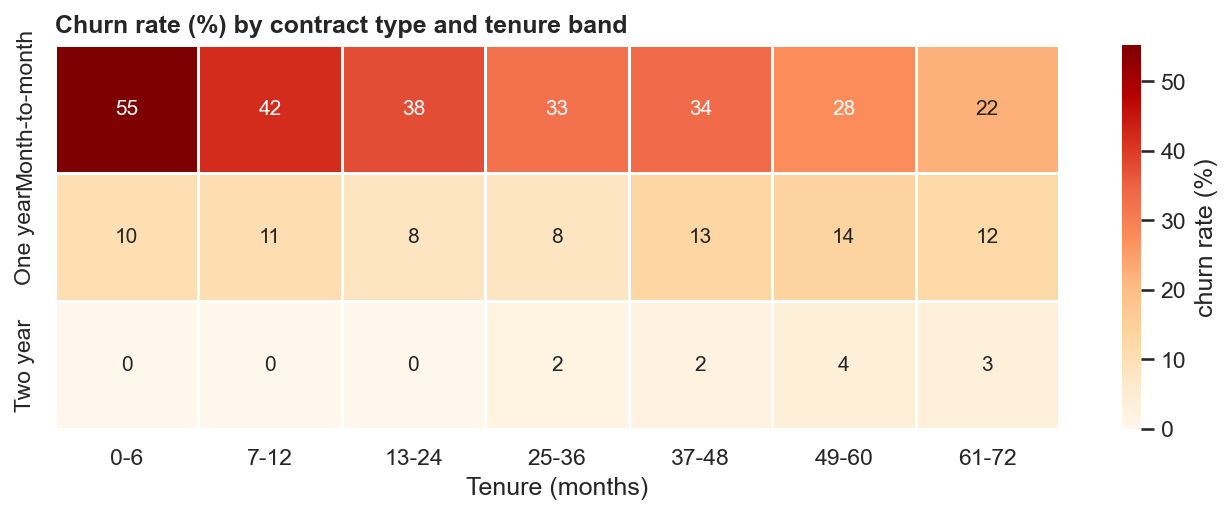


Two-year, <=24m: 158 customers, 0 churners


In [8]:
piv = df.pivot_table(index='Contract', columns=bands, values='churn_flag', aggfunc='mean')*100
cnt = df.pivot_table(index='Contract', columns=bands, values='churn_flag', aggfunc='size')
piv = piv.reindex(['Month-to-month','One year','Two year'])
cnt = cnt.reindex(['Month-to-month','One year','Two year'])
print('churn rate %'); print(piv.round(2).to_string(float_format=lambda v: f'{v:.2f}'))
print('\ncustomer counts'); print(cnt.fillna(0).astype(int).to_string())
m2m12 = df[(df.Contract=='Month-to-month') & (df.tenure<=12)]
print()
print(f'Month-to-month & tenure<=12 combined: {len(m2m12):,} customers, {int(m2m12.churn_flag.sum()):,} churners, {m2m12.churn_flag.mean()*100:.2f}% churn')

fig, ax = plt.subplots(figsize=(9,3.6))
sns.heatmap(piv, annot=True, fmt='.0f', cmap='OrRd', cbar_kws={'label':'churn rate (%)'},
            linewidths=.6, ax=ax, annot_kws={'fontsize':10})
ax.set_title('Churn rate (%) by contract type and tenure band', fontsize=12, fontweight='bold', loc='left')
ax.set_xlabel('Tenure (months)'); ax.set_ylabel('')
fig.tight_layout(); save_and_show(fig, '04_contract_tenure_heatmap')

print(f"\nTwo-year, <=24m: {int(cnt.loc['Two year'].iloc[:3].sum())} customers, "
      f"{int(df[(df.Contract=='Two year')&(df.tenure<=24)].churn_flag.sum())} churners")

## 8. Who are the most likely churners?

Ranked, explainable segments (no model). The **prime risk** cell — month-to-month, first year, fiber,
no tech support — is **11.83%** of the base but **31.67%** of all churn, at a **71.07%** churn rate
(2.68x base). That is the group a retention team should call first.

                         segment  customers  churners  churn_rate_%  pct_of_base  pct_of_churners  lift        mrr
  A. Month-to-month & tenure<=12       1994      1024         51.35        28.31            54.79  1.94 116,086.50
                B. + Fiber optic        916       643         70.20        13.01            34.40  2.65  75,183.15
    C. + no tech support (prime)        833       592         71.07        11.83            31.67  2.68  67,629.90
     D. Month-to-month & e-check       1850       994         53.73        26.27            53.18  2.02 138,730.55
E. Two-year & tenure>24 (safest)       1537        48          3.12        21.82             2.57  0.12  97,993.90


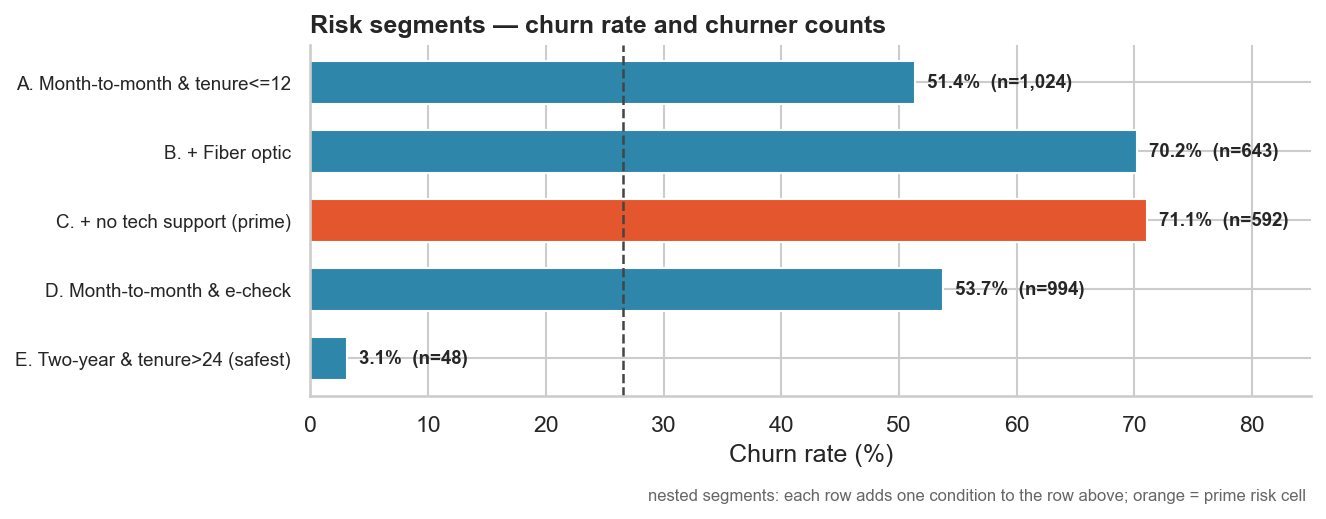

In [9]:
def seg(mask):
    return dict(customers=int(mask.sum()), churners=int(df.loc[mask,'churn_flag'].sum()),
                rate=df.loc[mask,'churn_flag'].mean()*100, mrr=df.loc[mask,'MonthlyCharges'].sum())

m2m, new = df.Contract=='Month-to-month', df.tenure<=12
fiber, notech = df.InternetService=='Fiber optic', df.TechSupport=='No'
rows = []
for name, mask in {
    'A. Month-to-month & tenure<=12': m2m & new,
    'B. + Fiber optic': m2m & new & fiber,
    'C. + no tech support (prime)': m2m & new & fiber & notech,
    'D. Month-to-month & e-check': m2m & (df.PaymentMethod=='Electronic check'),
    'E. Two-year & tenure>24 (safest)': (df.Contract=='Two year') & (df.tenure>24),
}.items():
    s = seg(mask); s['segment']=name
    s['pct_of_base']=s['customers']/n*100; s['pct_of_churners']=s['churners']/k*100
    s['lift']=s['rate']/(base*100); rows.append(s)
segs = pd.DataFrame(rows)[['segment','customers','churners','rate','pct_of_base','pct_of_churners','lift','mrr']]
segs.columns=['segment','customers','churners','churn_rate_%','pct_of_base','pct_of_churners','lift','mrr']
print(segs.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(9,3.8))
o = segs.iloc[::-1]
cols = [ACCENT if 'prime' in s else MUTED for s in o.segment]
ax.barh(range(len(o)), o['churn_rate_%'], color=cols, height=.62)
ax.set_yticks(range(len(o))); ax.set_yticklabels([s[:34] for s in o.segment], fontsize=9)
for i,(v,c) in enumerate(zip(o['churn_rate_%'], o.churners)):
    ax.text(v+1, i, f'{v:.1f}%  (n={c:,})', va='center', fontsize=9, fontweight='bold')
ax.axvline(base*100, ls='--', lw=1.2, color='#444')
ax.set_xlim(0,85); ax.set_xlabel('Churn rate (%)')
ax.annotate(f'overall churn {base*100:.2f}%', xy=(base*100, len(o)-0.45), xytext=(base*100+2, len(o)-0.45),
            fontsize=8.5, color='#444', va='center')
ax.text(0.995, -0.30, 'nested segments: each row adds one condition to the row above; orange = prime risk cell',
        transform=ax.transAxes, ha='right', fontsize=8, color='#666')
ax.set_title('Risk segments — churn rate and churner counts', fontsize=12, fontweight='bold', loc='left')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); save_and_show(fig, '05_risk_segments')

## 8b. Do services and demographics matter?

Service adoption separates customers far more cleanly than demographics do. Losing tech support or
online security roughly triples churn; gender does nothing at all (p = 0.487).

In [10]:
def tab(col, order=None):
    t = pd.crosstab(df[col], df.churn_flag)
    t['customers'] = t.sum(axis=1); t['churners'] = t[1]
    t['churn_rate_%'] = t['churners']/t['customers']*100
    chi2, pv, dof, exp = stats.chi2_contingency(t[[0,1]].values)
    V = math.sqrt(chi2/(len(df)*min(t.shape[0]-1,1)))
    print(f'-- {col}   chi2={chi2:8.1f}  p={pv:.3g}  CramersV={V:.3f}')
    out = t[['customers','churners','churn_rate_%']].round(2)
    print((out.reindex(order) if order else out.sort_values('churn_rate_%', ascending=False)).to_string())
    print()

for c in ['Contract','InternetService','TechSupport','OnlineSecurity','OnlineBackup','PaperlessBilling']:
    tab(c)
for c in ['gender','SeniorCitizen','Partner','Dependents']:
    tab(c)

-- Contract   chi2=  1184.6  p=5.86e-258  CramersV=0.410
churn_flag      customers  churners  churn_rate_%
Contract                                         
Month-to-month       3875      1655         42.71
One year             1473       166         11.27
Two year             1695        48          2.83

-- InternetService   chi2=   732.3  p=9.57e-160  CramersV=0.322
churn_flag       customers  churners  churn_rate_%
InternetService                                   
Fiber optic           3096      1297         41.89
DSL                   2421       459         18.96
No                    1526       113          7.40

-- TechSupport   chi2=   828.2  p=1.44e-180  CramersV=0.343
churn_flag           customers  churners  churn_rate_%
TechSupport                                           
No                        3473      1446         41.64
Yes                       2044       310         15.17
No internet service       1526       113          7.40

-- OnlineSecurity   chi2=   850.0  p

## 9. Driver model — and what it cannot tell us

Logistic regression on 30 dummy-encoded features. **Test AUC 0.8446** against a 73.46% majority-class
baseline: the model ranks risk usefully but this is a scoring aid, not an oracle.

One important honesty note: `MonthlyCharges` enters with a **negative** coefficient (-0.486) even though
its univariate churn rate rises with price. That is not a bug — `tenure`, `TotalCharges` and
`MonthlyCharges` are collinear, and `TotalCharges` absorbs the effect. The correct reading is "at equal
tenure and product mix, higher price alone is not the driver"; the univariate table in §6 must not be
read as "price causes churn".

AUC train=0.8487  test=0.8446
baseline (always predict retained): 73.46% full data / 73.45% test split | model accuracy = 80.79%
              precision    recall  f1-score   support

    retained       0.85      0.90      0.87      1552
     churned       0.66      0.56      0.61       561

    accuracy                           0.81      2113
   macro avg       0.76      0.73      0.74      2113
weighted avg       0.80      0.81      0.80      2113


Top 10 standardised drivers:
                             coef  odds_ratio
tenure                      -1.42        0.24
TotalCharges                 0.68        1.98
Contract_Two year           -0.59        0.56
InternetService_Fiber optic  0.57        1.77
MonthlyCharges              -0.49        0.61
Contract_One year           -0.27        0.76
StreamingMovies_Yes          0.18        1.19
StreamingTV_Yes              0.17        1.19
PaperlessBilling_Yes         0.17        1.18
MultipleLines_Yes            0.16        1.18

colline

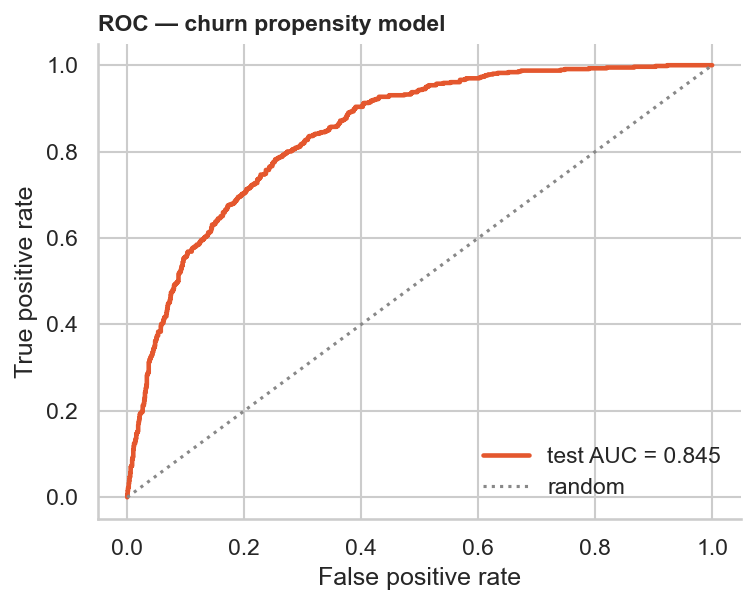

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, classification_report

feats = ['gender','SeniorCitizen','Partner','Dependents','tenure','PhoneService','MultipleLines',
         'InternetService','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport',
         'StreamingTV','StreamingMovies','Contract','PaperlessBilling','PaymentMethod',
         'MonthlyCharges','TotalCharges']
X = pd.get_dummies(df[feats], drop_first=True, dtype=float); y = df.churn_flag
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=.3,random_state=42,stratify=y)
sc = StandardScaler(); Xtr_s, Xte_s = sc.fit_transform(Xtr), sc.transform(Xte)
m = LogisticRegression(max_iter=5000, C=.5).fit(Xtr_s, ytr)
auc_tr, auc_te = roc_auc_score(ytr, m.predict_proba(Xtr_s)[:,1]), roc_auc_score(yte, m.predict_proba(Xte_s)[:,1])
print(f'AUC train={auc_tr:.4f}  test={auc_te:.4f}')
print(f'baseline (always predict retained): {(1-y.mean())*100:.2f}% full data / {(1-yte.mean())*100:.2f}% test split | model accuracy = {(m.predict(Xte_s)==yte).mean()*100:.2f}%')
print(classification_report(yte, m.predict(Xte_s), target_names=['retained','churned'], digits=2))

mf = LogisticRegression(max_iter=5000, C=1.0).fit(sc.fit_transform(X), y)
coefs = pd.Series(mf.coef_[0], index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)
print('\nTop 10 standardised drivers:')
print(pd.DataFrame({'coef':top.round(3), 'odds_ratio':np.exp(top).round(3)}).to_string())
print('\ncollinearity check (|r|):')
print(df[['tenure','MonthlyCharges','TotalCharges']].corr().round(3).to_string())

df['p_churn'] = mf.predict_proba(sc.transform(X))[:,1]
fpr,tpr,_ = roc_curve(yte, m.predict_proba(Xte_s)[:,1])
fig, ax = plt.subplots(figsize=(5.2,4.2))
ax.plot(fpr,tpr,lw=2.2,color=ACCENT,label=f'test AUC = {auc_te:.3f}')
ax.plot([0,1],[0,1],ls=':',color='#888',label='random')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('ROC — churn propensity model', fontsize=11, fontweight='bold', loc='left')
ax.legend(frameon=False, loc='lower right'); ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); save_and_show(fig, '06_roc')

## 10. Revenue risk

Churned customers carry **$139,130.85** of monthly recurring revenue — **30.50%** of the $456,116.60
total, or **$1,669,570.20** annualised. They also pay more per head ($74.44 vs $61.27), so churn is
skewed toward higher-value accounts rather than the cheap tail.

                           metric        value              note
                        MRR total   456,116.60                  
          MRR on churned accounts   139,130.85     30.50% of MRR
              Annualised exposure 1,669,570.20 12-month run-rate
     Avg monthly charge — churned        74.44                  
    Avg monthly charge — retained        61.27                  
 Avg historical revenue — churned     1,531.80                  
Avg historical revenue — retained     2,549.91                  

charge delta: churners pay $13.18 more per month

                customers  churners   mrr_lost  arr_exposure
Contract                                                    
Month-to-month   3,875.00  1,655.00 120,847.10  1,450,165.20
One year         1,473.00    166.00  14,118.45    169,421.40
Two year         1,695.00     48.00   4,165.30     49,983.60


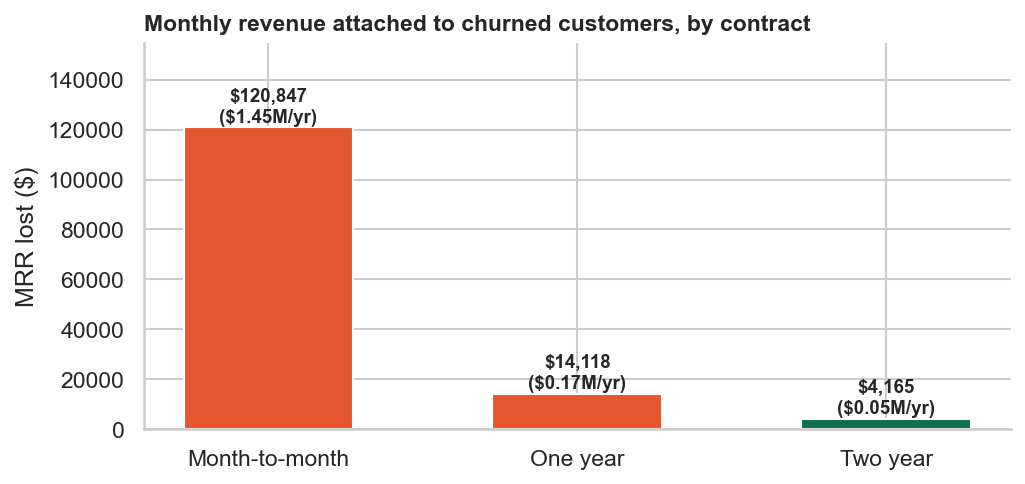

In [12]:
rr = pd.DataFrame([
 ('MRR total', mrr, ''),
 ('MRR on churned accounts', mrr_churned, f'{mrr_churned/mrr*100:.2f}% of MRR'),
 ('Annualised exposure', mrr_churned*12, '12-month run-rate'),
 ('Avg monthly charge — churned', df.loc[df.churn_flag==1,'MonthlyCharges'].mean(), ''),
 ('Avg monthly charge — retained', df.loc[df.churn_flag==0,'MonthlyCharges'].mean(), ''),
 ('Avg historical revenue — churned', df.loc[df.churn_flag==1,'TotalCharges'].mean(), ''),
 ('Avg historical revenue — retained', df.loc[df.churn_flag==0,'TotalCharges'].mean(), ''),
], columns=['metric','value','note'])
print(rr.to_string(index=False, float_format=lambda v: f'{v:,.2f}'))
print('')
print(f"charge delta: churners pay ${df.loc[df.churn_flag==1,'MonthlyCharges'].mean() - df.loc[df.churn_flag==0,'MonthlyCharges'].mean():.2f} more per month")

byc = df.groupby('Contract').apply(lambda g: pd.Series({
    'customers': len(g), 'churners': int(g.churn_flag.sum()),
    'mrr_lost': g.loc[g.churn_flag==1,'MonthlyCharges'].sum()}))
byc['arr_exposure'] = byc.mrr_lost*12
print('\n' + byc.sort_values('mrr_lost', ascending=False).round(2).to_string())

fig, ax = plt.subplots(figsize=(7,3.4))
b2 = byc.sort_values('mrr_lost', ascending=False)
ax.bar(b2.index, b2['mrr_lost'], color=[ACCENT,PAL[1],PAL[3]], width=.55)
for i,(v,a) in enumerate(zip(b2['mrr_lost'], b2['arr_exposure'])):
    ax.text(i, v+2200, f'${v:,.0f}\n(${a/1e6:.2f}M/yr)', ha='center', fontsize=9, fontweight='bold')
ax.set_ylabel('MRR lost ($)'); ax.set_ylim(0, b2.mrr_lost.max()*1.28)
ax.set_title('Monthly revenue attached to churned customers, by contract', fontsize=11, fontweight='bold', loc='left')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); save_and_show(fig, '07_revenue_risk')

## 11. Reconciliation against the SQL layer

Same metric, two independent implementations — pandas here, governed SQL views in `db/churn.db`.
Every row must match to 2 dp; the cell raises if any does not.

In [13]:
con = sqlite3.connect(f'{ROOT}/db/churn.db')
sql = pd.read_sql_query('SELECT customers, churners, churn_rate_pct, mrr_total, mrr_churned FROM v_kpi_overall', con)
con.close()

pairs = [
    ('customers',        n,                              sql.customers.iloc[0]),
    ('churners',         k,                              sql.churners.iloc[0]),
    ('churn_rate_pct',   base*100,                       sql.churn_rate_pct.iloc[0]),
    ('mrr_total',        mrr,                            sql.mrr_total.iloc[0]),
    ('mrr_churned',      mrr_churned,                    sql.mrr_churned.iloc[0]),
]
rec = pd.DataFrame([{'metric':a, 'pandas':round(b,2), 'sql':round(float(c),2),
                     'match': abs(b-float(c)) < 0.01} for a,b,c in pairs])
print(rec.to_string(index=False))
assert rec['match'].all(), 'RECONCILIATION FAILED - pandas and SQL disagree'
print('\nAll 5 headline metrics reconcile across pandas and SQL.')

# Band-level check: this is exactly where a right-closed pandas cut vs a left-closed
# SQL CASE drifts, with no error and no obviously wrong number.
con = sqlite3.connect(f'{ROOT}/db/churn.db')
sqlb = pd.read_sql_query('SELECT charge_band, customers, churners, churn_rate_pct FROM v_churn_by_charge_band', con)
con.close()
sqlb = sqlb.set_index('charge_band')
cmp = pd.DataFrame({
    'pandas_customers': cbt['customers'].astype(int),
    'sql_customers': sqlb['customers'].astype(int),
    'pandas_churners': cbt['churners'].astype(int),
    'sql_churners': sqlb['churners'].astype(int),
    'pandas_rate': cbt['churn_rate_%'].round(2),
    'sql_rate': sqlb['churn_rate_pct'].round(2),
})
print(cmp.to_string())
assert (cmp.pandas_customers == cmp.sql_customers).all(), 'charge band customer counts disagree'
assert (cmp.pandas_churners == cmp.sql_churners).all(), 'charge band churner counts disagree'
print('')
print('Charge-band boundaries agree band-for-band across pandas and SQL.')

        metric     pandas        sql  match
     customers   7,043.00   7,043.00   True
      churners   1,869.00   1,869.00   True
churn_rate_pct      26.54      26.54   True
     mrr_total 456,116.60 456,116.60   True
   mrr_churned 139,130.85 139,130.85   True

All 5 headline metrics reconcile across pandas and SQL.
       pandas_customers  sql_customers  pandas_churners  sql_churners  pandas_rate  sql_rate
<30                1653           1653              162           162         9.80      9.80
30-49               641            641              199           199        31.05     31.05
50-69              1158           1158              234           234        20.21     20.21
70-89              1847           1847              701           701        37.95     37.95
90+                1744           1744              573           573        32.86     32.86

Charge-band boundaries agree band-for-band across pandas and SQL.


## 12. Retention priorities — who to contact first

The tiers are not asserted; they come from the SQL `risk_points` scorecard
(`sql/01_data_exploration.sql`) whose cut-offs sit where the observed churn rate steps up
(`sql/04_retention_insights.sql`, BQ16). The scorecard is read back from the warehouse rather than
re-implemented here, so there is exactly one definition of "high risk" in the project.

           customers  churners  churn_rate_pct  pct_of_base  pct_of_churners  multiple_of_base   mrr_lost  arr_exposure
tier                                                                                                                   
1. HIGH     2,684.00  1,434.00           53.43        38.11            76.73              2.01 110,507.10  1,326,085.20
2. MEDIUM   1,480.00    293.00           19.80        21.01            15.68              0.75  18,084.15    217,009.80
3. LOW      2,879.00    142.00            4.93        40.88             7.60              0.19  10,539.60    126,475.20

totals: 7,043.0 customers, 1,869.0 churners
monotonic check: HIGH > MEDIUM > LOW  -> PASS


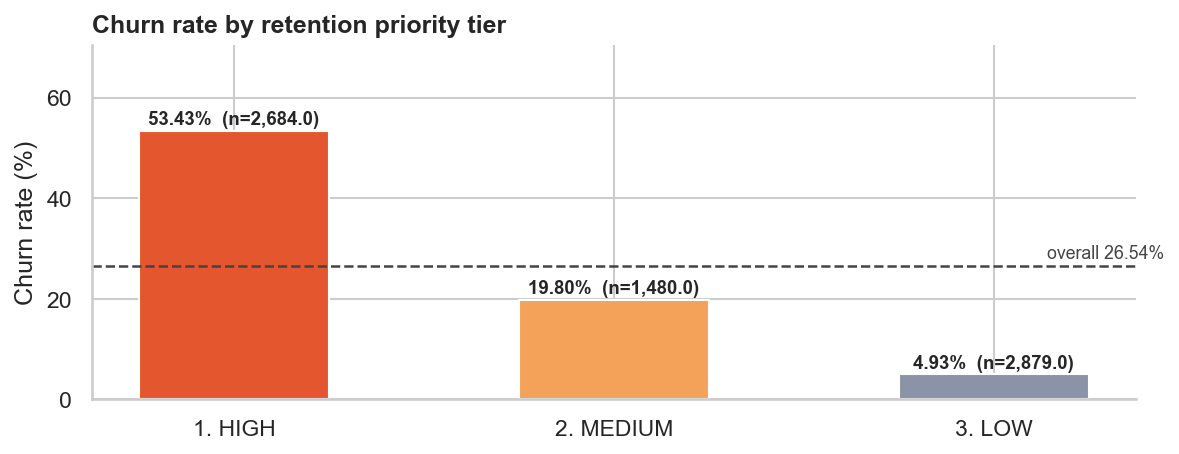

In [14]:
con = sqlite3.connect(f'{ROOT}/db/churn.db')
scored = pd.read_sql_query('SELECT customerID, risk_points FROM v_customers', con)
con.close()

df2 = df.merge(scored, left_on='customerID', right_on='customerID', how='left')
assert df2.risk_points.notna().all(), 'risk_points missing for some customers'

df2['tier'] = pd.cut(df2.risk_points, [-1, 4, 7, 99],
                     labels=['3. LOW', '2. MEDIUM', '1. HIGH'])

tiers = df2.groupby('tier', observed=True).apply(lambda g: pd.Series({
    'customers': len(g),
    'churners': int(g.churn_flag.sum()),
    'churn_rate_pct': round(g.churn_flag.mean()*100, 2),
    'pct_of_base': round(len(g)/len(df2)*100, 2),
    'pct_of_churners': round(g.churn_flag.sum()/df2.churn_flag.sum()*100, 2),
    'multiple_of_base': round(g.churn_flag.mean()/df2.churn_flag.mean(), 2),
    'mrr_lost': round(g.loc[g.churn_flag==1, 'MonthlyCharges'].sum(), 2),
    'arr_exposure': round(g.loc[g.churn_flag==1, 'MonthlyCharges'].sum()*12, 2),
}))
tiers = tiers.reindex(['1. HIGH', '2. MEDIUM', '3. LOW'])
print(tiers.to_string())
print()
print(f"totals: {tiers.customers.sum():,} customers, {tiers.churners.sum():,} churners")

rates = tiers.churn_rate_pct.tolist()
assert rates[0] > rates[1] > rates[2], f'TIERS NOT MONOTONE: {rates}'
print('monotonic check: HIGH > MEDIUM > LOW  -> PASS')

fig, ax = plt.subplots(figsize=(8, 3.2))
cols = [ACCENT, PAL[2], '#8a94a6']
bars = ax.bar(tiers.index, tiers.churn_rate_pct, color=cols, width=.5)
ax.axhline(base*100, ls='--', lw=1.2, color='#444')
ax.text(2.45, base*100+1.6, f'overall {base*100:.2f}%', fontsize=8.5, color='#444', ha='right')
for b, (r, n, c) in zip(bars, zip(tiers.churn_rate_pct, tiers.customers, tiers.churners)):
    label = f'{r:.2f}%  (n={n:,})'
    ax.text(b.get_x()+b.get_width()/2, r+1.2, label, ha='center', fontsize=9, fontweight='bold')
ax.set_ylabel('Churn rate (%)'); ax.set_ylim(0, max(tiers.churn_rate_pct)*1.32)
ax.set_title('Churn rate by retention priority tier', fontsize=12, fontweight='bold', loc='left')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); save_and_show(fig, '08_priority_tiers')

## 13. What the analysis supports

1. **Churn is a contract-and-tenure problem.** Month-to-month churns at 42.71% vs 2.83% on two-year;
   88.55% of churners are on month-to-month.
2. **The first year decides the relationship.** 52.94% churn in months 0-6, and 55.48% of all churn
   happens inside 12 months. Two-year customers show 0% churn through month 24.
3. **The prime risk cell is small and dense.** 833 customers (11.83% of base) at 71.07% churn,
   carrying 31.67% of all churners and $67,629.90 of MRR.
4. **Support and security subscriptions are retention products.** Tech-support holders churn at 15.17%
   vs 41.64% without; online-security at 14.61% vs 41.77%.
5. **Payment friction is a real signal.** Electronic check 45.29% vs 15.24% credit-card automatic.
6. **Demographics are noise.** Gender 26.92% vs 26.16% (p = 0.487). Senior status is a real but weaker
   signal (41.68% vs 23.61%).
7. **$139,130.85 of MRR walked out monthly** — 30.50% of MRR — on accounts that paid $13.18 more per
   month than those who stayed.

**What this cannot support:** no time dimension, so no trend, no seasonality, no cohort decay curve;
no cost-to-serve, so no CLV or true profitability; no acquisition data, so no CAC payback. Revenue
figures are exposure, not loss.